# Automating the Experiment

Python companion to the AMO Toolkit page [Automating the Experiment](https://amotoolkit.com/pages/automation.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/automation.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. The power-servo simulator
A line-by-line port of the page's simulation, including its random-number generator, so the same settings give the same numbers.

Laser power: 3% mains ripple, slow drift, an 8% drop at 20 ms and 0.3% fast noise; photodiodes with 0.1% noise; the AOM is a 0.5 µs first-order response after the loop delay, clamped between 0 and 1. Servo types: **P** (gain 10 with a low-pass), **I** (integrator with crossover f<sub>c</sub>), **PI** (K<sub>p</sub> = 0.5, K<sub>i</sub> = 2πf<sub>c</sub>). Feedforward: none, a setpoint model, or setpoint plus a pick-off photodiode with a 5% calibration error.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class LCG:                                   # the page's generator: s <- (1664525 s + 1013904223) mod 2^32
    def __init__(self, seed): self.s = seed & 0xFFFFFFFF
    def __call__(self):
        self.s = (self.s * 1664525 + 1013904223) & 0xFFFFFFFF
        return self.s / 4294967296
    def gauss(self):
        u = self() or 1e-12; v = self()
        return np.sqrt(-2 * np.log(u)) * np.cos(2 * np.pi * v)

def simulate(mode="i", ff="none", fc=1e3, delay=1e-6, mains=60, keep=False):
    dt, T, TP, CAL = 0.25e-6, 50e-3, 0.5e-6, 0.05
    N = round(T / dt); r = LCG(7)
    wc = 2 * np.pi * fc; nd = max(1, round(delay / dt))
    buf = [0.0] * nd; bi = 0; a = 0.5; integ = 0.0; y = 0.0
    Kp, wlp, Ki, Kp2 = 10, wc / 10, wc, 0.5
    if mode != "off" and ff == "none":
        integ = 0 if mode == "p" else 0.5; y = 0.45 if mode == "p" else 0
    e2 = n2 = stepE = nStep = ramp = sat = 0
    trace = np.zeros(N // 40) if keep else None
    for i in range(N):
        t = i * dt
        R = 0.5 if t < 30e-3 else (0.5 + 0.3 * (t - 30e-3) / 5e-3 if t < 35e-3 else 0.8)
        PL = (1 + 0.03 * np.sin(2 * np.pi * mains * t) + 0.015 * np.sin(2 * np.pi * 7 * t + 1.3)
              + 0.01 * np.sin(2 * np.pi * 23 * t + 4.1) + (-0.08 if t > 20e-3 else 0) + 0.003 * r.gauss())
        PLm = PL + 0.001 * r.gauss()
        uff = R / (PLm * (1 + CAL)) if ff == "pick" else (R if (ff == "set" or mode == "off") else 0)
        P = PL * a; m = P + 0.001 * r.gauss(); e = R - m
        if mode == "off": u = uff
        elif mode == "p": y += dt * wlp * (Kp * e - y); u = uff + y
        elif mode == "i":
            u = uff + integ
            if 0 < u < 1: integ += wc * e * dt
        else:
            u = uff + Kp2 * e + integ
            if 0 < u < 1: integ += Ki * e * dt
        us = min(1, max(0, u))
        ud = buf[bi]; buf[bi] = us; bi = (bi + 1) % nd
        if i < nd: ud = us
        a += (ud - a) * dt / TP
        if keep and i % 40 == 0: trace[i // 40] = P
        if t > 2e-3:
            er = (P - R) / R; e2 += er * er; n2 += 1
            if us <= 0 or us >= 1: sat += 1
            if 20.5e-3 < t < 25e-3: stepE += abs(er); nStep += 1
            if 30e-3 < t < 36e-3: ramp = max(ramp, abs(er))
    out = dict(rms_pct=np.sqrt(e2 / n2) * 100, after_drop_pct=stepE / nStep * 100, ramp_pct=ramp * 100, unstable=sat / n2 > 0.2)
    if keep: out["trace"] = trace
    return out

fc_page = 100 * 3000 ** 0.29   # the page's log slider at its default position: 1.02 kHz, shown as "1 kHz"
base = simulate(fc=fc_page)    # page default: I servo, 1 µs delay, no feedforward, 60 Hz
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in base.items()})

{'rms_pct': np.float64(0.651), 'after_drop_pct': np.float64(0.27), 'ramp_pct': np.float64(3.054), 'unstable': False}

## 2. Compare the strategies
This takes a few seconds: each run is 200 000 time steps in plain Python.

off  none      1 kHz: rms 6.61%  after drop 4.02%  ramp 10.3%
  p  none      1 kHz: rms 9.68%  after drop 9.52%  ramp 12.6%
  i  none      1 kHz: rms 0.66%  after drop 0.27%  ramp 3.1%
 pi  none      1 kHz: rms 0.64%  after drop 0.29%  ramp 3.0%
  i   set      1 kHz: rms 0.46%  after drop 0.27%  ramp 1.5%
 pi  pick     10 kHz: rms 0.43%  after drop 0.34%  ramp 2.1%
  i  none    100 kHz: rms 0.36%  after drop 0.28%  ramp 1.6%

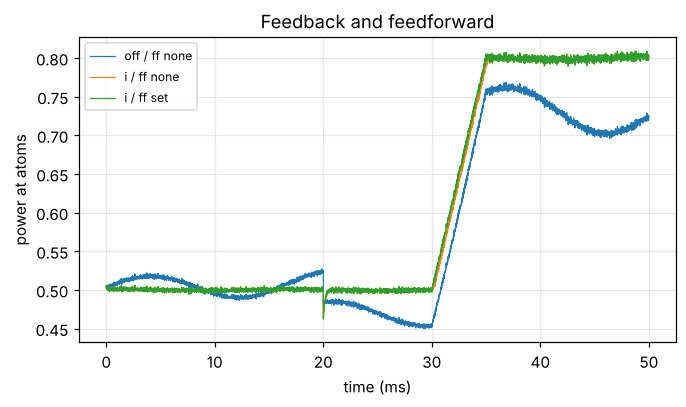

In [2]:
cases = [("off", "none", 1e3), ("p", "none", 1e3), ("i", "none", 1e3), ("pi", "none", 1e3),
         ("i", "set", 1e3), ("pi", "pick", 1e4), ("i", "none", 1e5)]
runs = {}
for mode, ff, fc in cases:
    s = simulate(mode, ff, fc, keep=True); runs[(mode, ff, fc)] = s
    print(f"{mode:>3} {ff:>5} {fc/1e3:6.0f} kHz: rms {s['rms_pct']:.2f}%  after drop {s['after_drop_pct']:.2f}%  ramp {s['ramp_pct']:.1f}%")
t = np.arange(len(runs[cases[0]]["trace"])) * 10e-3
for key in (cases[0], cases[2], cases[4]):
    plt.plot(t, runs[key]["trace"], lw=0.8, label=f"{key[0]} / ff {key[1]}")
plt.xlabel("time (ms)"); plt.ylabel("power at atoms"); plt.legend(fontsize=8); plt.title("Feedback and feedforward")

## 3. The stability limit
A pure integrator with total delay τ runs out of phase margin near f ≈ 1/(4τ). Here τ is the loop delay plus the 0.5 µs AOM response. (Course problem, week 13.)

In [3]:
for d in (0.5e-6, 1e-6, 2e-6):
    lim = 1 / (4 * (d + 0.5e-6))
    lo, hi = simulate("i", fc=0.6 * lim, delay=d)["unstable"], simulate("i", fc=1.4 * lim, delay=d)["unstable"]
    print(f"delay {d*1e6:.1f} µs: estimate {lim/1e3:.0f} kHz → unstable at 0.6×? {lo}   at 1.4×? {hi}")

delay 0.5 µs: estimate 250 kHz → unstable at 0.6×? False   at 1.4×? True
delay 1.0 µs: estimate 167 kHz → unstable at 0.6×? False   at 1.4×? True
delay 2.0 µs: estimate 100 kHz → unstable at 0.6×? False   at 1.4×? True

## 4. Quadrant photodiode error signal
For a Gaussian spot of 1/e² radius w on an ideal split detector, $X = \mathrm{erf}(\sqrt2\,x/w)$: linear for |x| ≲ w/2, then saturating.

{'X': np.float64(0.8014572063133379), 'Y': np.float64(-0.524949475946047)}

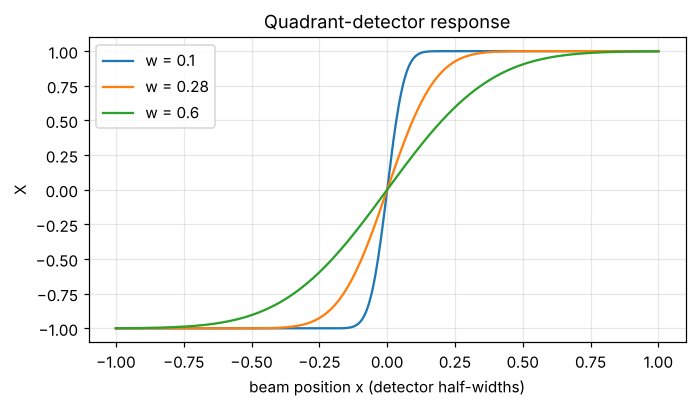

In [4]:
from scipy.special import erf
x = np.linspace(-1, 1, 400)
for w in (0.1, 0.28, 0.6):
    plt.plot(x, erf(np.sqrt(2) * x / w), label=f"w = {w}")
plt.xlabel("beam position x (detector half-widths)"); plt.ylabel("X"); plt.legend(); plt.title("Quadrant-detector response")
quad = dict(X=erf(np.sqrt(2) * 0.18 / 0.28), Y=erf(np.sqrt(2) * -0.1 / 0.28))
print(quad)

## 5. Optimisers
For real optimisation runs use [M-LOOP](https://github.com/michaelhush/M-LOOP), which provides Gaussian-process, neural-net, differential-evolution, Nelder–Mead and random learners and talks to an experiment through files or Python; the page's §06 workflow applies unchanged.

## 6. Check against the page
Readouts the live page showed for these settings (I servo, 1 kHz, 1 µs; and the quadrant detector's start position).

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(rms=base["rms_pct"], after_drop=base["after_drop_pct"], ramp=base["ramp_pct"], X=quad["X"], Y=quad["Y"])
DECIMALS = dict(rms=2, after_drop=2, ramp=1, X=3, Y=3)
page = dict(rms=0.65, after_drop=0.27, ramp=3.1, X=0.801, Y=-0.525)
check(ours, page)

         rms: notebook 0.6509       page 0.65       OK
  after_drop: notebook 0.2695       page 0.27       OK
        ramp: notebook 3.054        page 3.1        OK
           X: notebook 0.8015       page 0.801      OK
           Y: notebook -0.5249      page -0.525     OK
All values match the page.